# Laboratorium 2

In [1]:
import csv, copy
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 0
EPOCHS = 12      # wspólny budżet epok dla porównywanych wariantów
BS = 128
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.14.1+cpu | urządzenie: cpu


## 1. Dane

In [2]:
mean, std = 0.2860, 0.3530
norm = transforms.Normalize((mean,), (std,))
tf_plain = transforms.Compose([transforms.ToTensor(), norm])
tf_flip = transforms.Compose([transforms.RandomHorizontalFlip(), transforms.ToTensor(), norm])
tf_flipcrop = transforms.Compose([transforms.RandomHorizontalFlip(),
                                  transforms.RandomCrop(28, padding=4),
                                  transforms.ToTensor(), norm])

def fm(train, tf):
    return torchvision.datasets.FashionMNIST("./data", train=train, download=True, transform=tf)

train_sets = {"plain": fm(True, tf_plain), "flip": fm(True, tf_flip), "flipcrop": fm(True, tf_flipcrop)}
test_ds = fm(False, tf_plain)

def to_tensors(ds):
    X = ((ds.data.float() / 255.0 - mean) / std).unsqueeze(1).to(device)
    y = ds.targets.to(device)
    return X, y

X_tr, y_tr = to_tensors(train_sets["plain"])
X_te, y_te = to_tensors(test_ds)
N_TR = len(X_tr)
print("Trening:", N_TR, "| Test:", len(X_te))

Trening: 60000 | Test: 10000


## 2. Model i funkcje pomocnicze

In [3]:
class MLP(nn.Module):
    def __init__(self, in_dim=28*28, hidden=(256, 128), n_classes=10, use_bn=False, p_drop=0.0):
        super().__init__()
        layers, prev = [nn.Flatten()], in_dim
        for h in hidden:
            layers.append(nn.Linear(prev, h))
            if use_bn:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if p_drop > 0:
                layers.append(nn.Dropout(p_drop))
            prev = h
        layers.append(nn.Linear(prev, n_classes))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

def count_params(m):
    return sum(p.numel() for p in m.parameters())

@torch.no_grad()
def evaluate(model, X, y, bs=2000):
    model.eval()
    loss, correct = 0.0, 0
    crit = nn.CrossEntropyLoss(reduction="sum")
    for i in range(0, len(X), bs):
        out = model(X[i:i+bs])
        loss += crit(out, y[i:i+bs]).item()
        correct += (out.argmax(1) == y[i:i+bs]).sum().item()
    return loss / len(X), correct / len(X)

DEFAULT = dict(aug="plain", bn=False, p_drop=0.0, wd=0.0, opt="adam", sched=None, lr=None)

def batch_iter(dl, gen):
    if dl is None:  # bez augmentacji: batche z tensorów na urządzeniu
        idx = torch.randperm(N_TR, generator=gen)
        for i in range(0, N_TR, BS):
            j = idx[i:i+BS].to(device)
            yield X_tr[j], y_tr[j]
    else:           # z augmentacją: transformacje torchvision na PIL
        for xb, yb in dl:
            yield xb.to(device), yb.to(device)

def run_training(cfg, epochs=EPOCHS, seed=SEED, patience=None, verbose=False):
    c = {**DEFAULT, **cfg}
    torch.manual_seed(seed)
    model = MLP(use_bn=c["bn"], p_drop=c["p_drop"]).to(device)
    crit = nn.CrossEntropyLoss()
    lr = c["lr"] if c["lr"] is not None else (1e-3 if c["opt"] == "adam" else 1e-2)
    if c["opt"] == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=c["wd"])
    else:
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=c["wd"])
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=max(1, epochs // 3), gamma=0.5) if c["sched"] == "step" else None
    gen = torch.Generator()
    gen.manual_seed(seed)
    dl = None
    if c["aug"] != "plain":
        dl = DataLoader(train_sets[c["aug"]], batch_size=BS, shuffle=True, generator=gen, num_workers=2)
    h = {k: [] for k in ["train_loss_run", "train_loss", "train_acc", "test_loss", "test_acc"]}
    best_loss, best_state, best_ep, wait = float("inf"), None, 0, 0
    for ep in range(1, epochs + 1):
        model.train()
        run = 0.0
        for xb, yb in batch_iter(dl, gen):
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            opt.step()
            run += loss.item() * yb.numel()
        if sched:
            sched.step()
        trl, tra = evaluate(model, X_tr, y_tr)   # czysty trening, tryb eval
        tel, tea = evaluate(model, X_te, y_te)
        h["train_loss_run"].append(run / N_TR); h["train_loss"].append(trl); h["train_acc"].append(tra)
        h["test_loss"].append(tel); h["test_acc"].append(tea)
        if verbose:
            print(f"Epoka {ep:2d} | trening(eval) {trl:.3f} | test {tel:.3f} | acc {tea*100:.2f}%")
        if patience is not None:
            if tel < best_loss - 1e-4:
                best_loss, best_ep, wait = tel, ep, 0
                best_state = copy.deepcopy(model.state_dict())
            else:
                wait += 1
                if wait >= patience:
                    break
    h["final_idx"] = (best_ep - 1) if patience is not None else (epochs - 1)
    h["params"] = count_params(model)
    return h

def summarize(name, h):
    i = h["final_idx"]
    return dict(config=name,
                acc=h["test_acc"][i] * 100,
                best_acc=max(h["test_acc"]) * 100,
                train_acc=h["train_acc"][i] * 100,
                gap_acc=(h["train_acc"][i] - h["test_acc"][i]) * 100,
                gap_loss=h["test_loss"][i] - h["train_loss"][i],
                epochs=i + 1)

def print_table(rows, title=""):
    if title:
        print(title)
    print(f"{'konfiguracja':<46}{'acc test [%]':>13}{'(best)':>9}{'acc trening':>13}{'przerwa acc [pp]':>18}{'przerwa loss':>14}")
    for r in rows:
        print(f"{r['config']:<46}{r['acc']:>13.2f}{r['best_acc']:>9.2f}{r['train_acc']:>13.2f}{r['gap_acc']:>18.2f}{r['gap_loss']:>14.3f}")

print("Parametry baseline:", count_params(MLP()))

Parametry baseline: 235146


## 3. Baseline oraz pojedyncze ulepszenia
Każdy wariant różni się od baseline dokładnie jednym czynnikiem: odbicie poziome / odbicie + przesunięcie, BatchNorm, dropout 0.3, weight decay 5e-4 (L2 w Adam), scheduler StepLR (×0.5 co 4 epoki), optymalizator SGD+momentum (lr=0.01).

In [4]:
SINGLES = {
    "baseline":                         {},
    "+aug: odbicie":                    {"aug": "flip"},
    "+aug: odbicie + przesunięcie":     {"aug": "flipcrop"},
    "+BatchNorm":                       {"bn": True},
    "+dropout 0.3":                     {"p_drop": 0.3},
    "+weight decay 5e-4":               {"wd": 5e-4},
    "+scheduler StepLR":                {"sched": "step"},
    "optymalizator: SGD+momentum":      {"opt": "sgd"},
}
HIST, RES, CFG = {}, {}, {}
for name, cfg in SINGLES.items():
    print("trening:", name, flush=True)
    HIST[name] = run_training(cfg)
    RES[name] = summarize(name, HIST[name])
    CFG[name] = cfg
print_table([RES[n] for n in SINGLES], "\n== POJEDYNCZE CZYNNIKI (12 epok) ==")

trening: baseline
trening: +aug: odbicie
trening: +aug: odbicie + przesunięcie
trening: +BatchNorm
trening: +dropout 0.3
trening: +weight decay 5e-4
trening: +scheduler StepLR
trening: optymalizator: SGD+momentum

== POJEDYNCZE CZYNNIKI (12 epok) ==
konfiguracja                                   acc test [%]   (best)  acc trening  przerwa acc [pp]  przerwa loss
baseline                                              89.21    89.21        93.88              4.67         0.182
+aug: odbicie                                         88.78    89.02        92.49              3.71         0.126
+aug: odbicie + przesunięcie                          83.74    84.23        84.53              0.79         0.028
+BatchNorm                                            89.04    89.56        95.30              6.25         0.202
+dropout 0.3                                          88.38    88.38        91.47              3.09         0.102
+weight decay 5e-4                                    88.75    88.

## 4. Kombinacje
- **BatchNorm + dropout**
- **wszystko naraz**
- **kombinacja „zwycięzców”**

In [5]:
base_acc = RES["baseline"]["acc"]
combo, winners = {}, []
aug_c = [n for n in ("+aug: odbicie", "+aug: odbicie + przesunięcie") if RES[n]["acc"] > base_acc]
if aug_c:
    w = max(aug_c, key=lambda n: RES[n]["acc"])
    combo.update(SINGLES[w]); winners.append(w.replace("+", ""))
for n in ("+BatchNorm", "+dropout 0.3", "+weight decay 5e-4", "+scheduler StepLR"):
    if RES[n]["acc"] > base_acc:
        combo.update(SINGLES[n]); winners.append(n.replace("+", ""))

COMBOS = {
    "BN + dropout 0.3": {"bn": True, "p_drop": 0.3},
    "wszystko (aug+crop, BN, drop, wd 1e-4, StepLR)": {"aug": "flipcrop", "bn": True, "p_drop": 0.3, "wd": 1e-4, "sched": "step"},
}
if winners:
    COMBOS["kombinacja zwycięzców: " + ", ".join(winners)] = combo

for name, cfg in COMBOS.items():
    print("trening:", name, flush=True)
    HIST[name] = run_training(cfg)
    RES[name] = summarize(name, HIST[name])
    CFG[name] = cfg
print_table([RES[n] for n in COMBOS], "\n== KOMBINACJE (12 epok) ==")

trening: BN + dropout 0.3
trening: wszystko (aug+crop, BN, drop, wd 1e-4, StepLR)
trening: kombinacja zwycięzców: scheduler StepLR

== KOMBINACJE (12 epok) ==
konfiguracja                                   acc test [%]   (best)  acc trening  przerwa acc [pp]  przerwa loss
BN + dropout 0.3                                      88.99    89.24        92.72              3.73         0.118
wszystko (aug+crop, BN, drop, wd 1e-4, StepLR)        82.57    82.85        83.47              0.90         0.025
kombinacja zwycięzców: scheduler StepLR               89.58    89.58        94.66              5.08         0.168


## 5. Zestawienie wyników i najlepsza konfiguracja
Tabela: konfiguracja, accuracy testowa, przerwa train–test. Zapisywana także do `wyniki.csv`.

In [6]:
rows = [RES[n] for n in list(SINGLES) + list(COMBOS)]
print_table(rows, "== WSZYSTKIE KONFIGURACJE (ten sam budżet: %d epok) ==" % EPOCHS)

with open("wyniki.csv", "w", newline="", encoding="utf-8") as f:
    wr = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
    wr.writeheader(); wr.writerows(rows)

best_name = max(RES, key=lambda n: RES[n]["acc"])
print("\nNajlepsza konfiguracja (wg accuracy testowej po ostatniej epoce):", best_name,
      f"-> {RES[best_name]['acc']:.2f}%")

== WSZYSTKIE KONFIGURACJE (ten sam budżet: 12 epok) ==
konfiguracja                                   acc test [%]   (best)  acc trening  przerwa acc [pp]  przerwa loss
baseline                                              89.21    89.21        93.88              4.67         0.182
+aug: odbicie                                         88.78    89.02        92.49              3.71         0.126
+aug: odbicie + przesunięcie                          83.74    84.23        84.53              0.79         0.028
+BatchNorm                                            89.04    89.56        95.30              6.25         0.202
+dropout 0.3                                          88.38    88.38        91.47              3.09         0.102
+weight decay 5e-4                                    88.75    88.75        91.84              3.09         0.110
+scheduler StepLR                                     89.58    89.58        94.66              5.08         0.168
optymalizator: SGD+momentum      

## 6. Krzywe uczenia: baseline vs najlepszy wariant
Linia przerywana = strata treningowa (czysty zbiór, `eval()`), ciągła = strata testowa. Cienka linia kropkowana = strata „bieżąca” z trybu `train()` (z dropoutem/augmentacją).

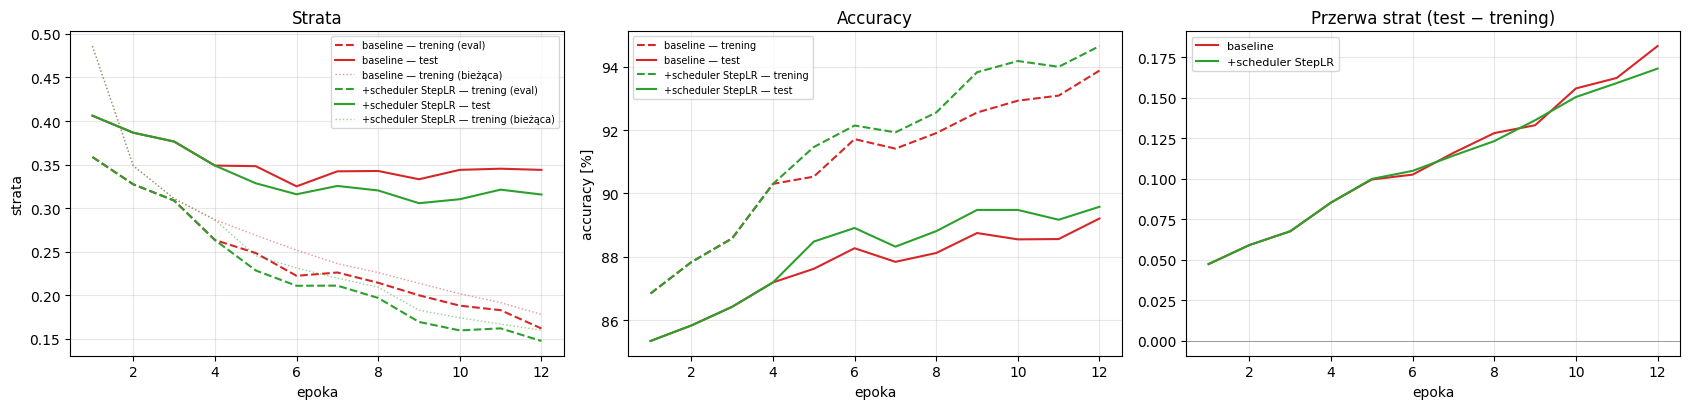

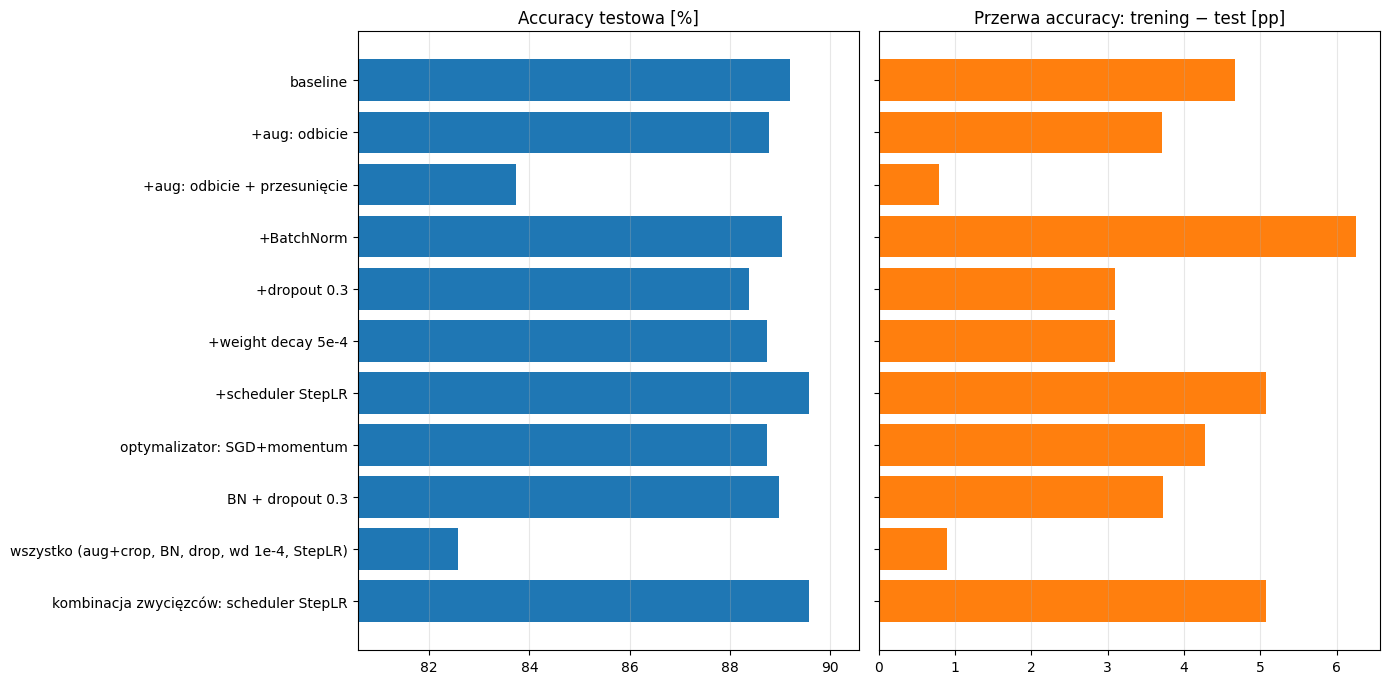

In [7]:
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(17, 4.2))
ep = range(1, EPOCHS + 1)
for name, c in [("baseline", "tab:red"), (best_name, "tab:green")]:
    h = HIST[name]
    a1.plot(ep, h["train_loss"], "--", color=c, label=f"{name} — trening (eval)")
    a1.plot(ep, h["test_loss"], "-", color=c, label=f"{name} — test")
    a1.plot(ep, h["train_loss_run"], ":", color=c, alpha=0.5, lw=1, label=f"{name} — trening (bieżąca)")
    a2.plot(ep, [a * 100 for a in h["train_acc"]], "--", color=c, label=f"{name} — trening")
    a2.plot(ep, [a * 100 for a in h["test_acc"]], "-", color=c, label=f"{name} — test")
    a3.plot(ep, [(t - r) for t, r in zip(h["test_loss"], h["train_loss"])], color=c, label=name)
a1.set_title("Strata"); a1.set_xlabel("epoka"); a1.set_ylabel("strata"); a1.legend(fontsize=7)
a2.set_title("Accuracy"); a2.set_xlabel("epoka"); a2.set_ylabel("accuracy [%]"); a2.legend(fontsize=7)
a3.set_title("Przerwa strat (test − trening)"); a3.set_xlabel("epoka"); a3.axhline(0, color="gray", lw=0.5); a3.legend(fontsize=8)
for a in (a1, a2, a3):
    a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("krzywe_baseline_vs_best.png", dpi=130); plt.show()

names = list(RES)
fig, (b1, b2) = plt.subplots(1, 2, figsize=(14, 0.45 * len(names) + 2), sharey=True)
b1.barh(names, [RES[n]["acc"] for n in names], color="tab:blue")
b1.set_xlim(min(RES[n]["acc"] for n in names) - 2, max(RES[n]["acc"] for n in names) + 1)
b1.set_title("Accuracy testowa [%]"); b1.invert_yaxis()
b2.barh(names, [RES[n]["gap_acc"] for n in names], color="tab:orange")
b2.set_title("Przerwa accuracy: trening − test [pp]")
for b in (b1, b2):
    b.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.savefig("porownanie_konfiguracji.png", dpi=130); plt.show()

## 7. Przerwa train–test: baseline vs najlepszy wariant
Poniższa komórka liczy wnioski z faktycznych wyników

In [8]:
b, t = RES["baseline"], RES[best_name]
print(f"BASELINE : acc test {b['acc']:.2f}% | acc trening {b['train_acc']:.2f}% | przerwa acc {b['gap_acc']:.2f} pp | przerwa loss {b['gap_loss']:.3f}")
print(f"NAJLEPSZY: {best_name}")
print(f"           acc test {t['acc']:.2f}% | acc trening {t['train_acc']:.2f}% | przerwa acc {t['gap_acc']:.2f} pp | przerwa loss {t['gap_loss']:.3f}")
print()
if best_name == "baseline":
    print("Żaden wariant nie pobił baseline w tym budżecie epok (por. uwagę o niedouczeniu niżej).")
else:
    print(f"Zmiana accuracy testowej: {t['acc'] - b['acc']:+.2f} pp")
    if b["gap_acc"] > 0:
        print(f"Przerwa accuracy: {b['gap_acc']:.2f} -> {t['gap_acc']:.2f} pp ({(t['gap_acc'] - b['gap_acc']) / b['gap_acc'] * 100:+.0f}%)")
    if b["gap_loss"] > 0:
        print(f"Przerwa straty:   {b['gap_loss']:.3f} -> {t['gap_loss']:.3f} ({(t['gap_loss'] - b['gap_loss']) / b['gap_loss'] * 100:+.0f}%)")
    smaller = t["gap_loss"] < b["gap_loss"] and t["gap_acc"] < b["gap_acc"]
    print("Wniosek:", "przeuczenie zmalało (mniejsza przerwa w stracie i accuracy)." if smaller
          else "przerwa nie zmalała jednoznacznie w obu miarach — patrz tabela.")
# rosnąca strata testowa przy malejącej treningowej = klasyczny objaw przeuczenia baseline
hb = HIST["baseline"]
i_min = min(range(EPOCHS), key=lambda i: hb["test_loss"][i])
print(f"\nBaseline: minimum straty testowej w epoce {i_min + 1} ({hb['test_loss'][i_min]:.3f}), w epoce {EPOCHS}: {hb['test_loss'][-1]:.3f}")

# diagnostyka niedouczenia: wysoka strata treningowa przy małej przerwie
under = [n for n in RES if RES[n]["train_acc"] < RES["baseline"]["train_acc"] - 3 and RES[n]["acc"] < RES["baseline"]["acc"]]
if under:
    print("\nWarianty z niższą accuracy testową, u których maleje też accuracy treningowa (>3 pp) — to niedouczenie, "
          "a nie mniejsze przeuczenie; przy 12 epokach silna regularyzacja MLP często nie zdąża się zbiec:")
    for n in under:
        print("  -", n)

BASELINE : acc test 89.21% | acc trening 93.88% | przerwa acc 4.67 pp | przerwa loss 0.182
NAJLEPSZY: +scheduler StepLR
           acc test 89.58% | acc trening 94.66% | przerwa acc 5.08 pp | przerwa loss 0.168

Zmiana accuracy testowej: +0.37 pp
Przerwa accuracy: 4.67 -> 5.08 pp (+9%)
Przerwa straty:   0.182 -> 0.168 (-8%)
Wniosek: przerwa nie zmalała jednoznacznie w obu miarach — patrz tabela.

Baseline: minimum straty testowej w epoce 6 (0.325), w epoce 12: 0.344

Warianty z niższą accuracy testową, u których maleje też accuracy treningowa (>3 pp) — to niedouczenie, a nie mniejsze przeuczenie; przy 12 epokach silna regularyzacja MLP często nie zdąża się zbiec:
  - +aug: odbicie + przesunięcie
  - wszystko (aug+crop, BN, drop, wd 1e-4, StepLR)


## 8. Zakres dodatkowy
### 8a. Przegląd współczynnika uczenia (baseline, 4 epoki)

lr=0.1     -> acc po 4 epokach 10.01% (best 47.92%)
lr=0.01    -> acc po 4 epokach 86.25% (best 86.25%)
lr=0.001   -> acc po 4 epokach 87.19% (best 87.19%)
lr=0.0001  -> acc po 4 epokach 85.15% (best 85.15%)


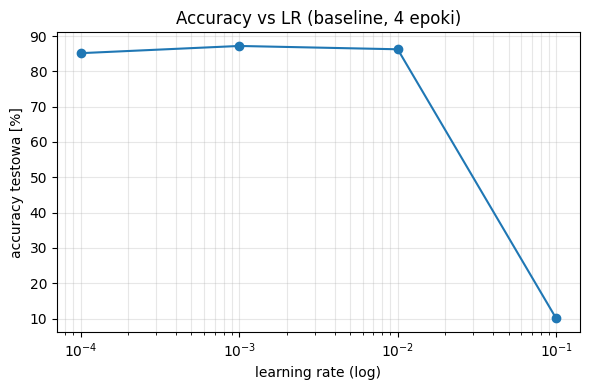

In [9]:
lrs = [1e-1, 1e-2, 1e-3, 1e-4]
lr_rows = []
for lr in lrs:
    h = run_training({"lr": lr}, epochs=4)
    lr_rows.append((lr, h["test_acc"][-1] * 100, max(h["test_acc"]) * 100))
    print(f"lr={lr:<7} -> acc po 4 epokach {lr_rows[-1][1]:.2f}% (best {lr_rows[-1][2]:.2f}%)")

plt.figure(figsize=(6, 4))
plt.semilogx([r[0] for r in lr_rows], [r[1] for r in lr_rows], "o-")
plt.xlabel("learning rate (log)"); plt.ylabel("accuracy testowa [%]"); plt.title("Accuracy vs LR (baseline, 4 epoki)")
plt.grid(True, which="both", alpha=0.3); plt.tight_layout(); plt.savefig("acc_vs_lr.png", dpi=130); plt.show()

### 8b. Early stopping
Zatrzymanie po 3 epokach bez poprawy straty testowej (max 30 epok), przywrócenie wag z najlepszej epoki. monitorowanie zbioru testowego daje optymistyczne wyniki, budżet epok jest tu inny niż w sekcji 3, więc wyników nie porównujemy z tamtą tabelą.

In [10]:
ES_ROWS = []
for name in ["baseline", best_name]:
    h = run_training(CFG[name], epochs=30, patience=3)
    ES_ROWS.append(summarize(name + " + early stopping", h))
    print(f"{name}: zatrzymano po {len(h['test_acc'])} epokach, najlepsza epoka {h['final_idx'] + 1}")
print_table(ES_ROWS, "\n== EARLY STOPPING (max 30 epok, patience=3) ==")

baseline: zatrzymano po 9 epokach, najlepsza epoka 6
+scheduler StepLR: zatrzymano po 9 epokach, najlepsza epoka 6

== EARLY STOPPING (max 30 epok, patience=3) ==
konfiguracja                                   acc test [%]   (best)  acc trening  przerwa acc [pp]  przerwa loss
baseline + early stopping                             88.27    88.75        91.72              3.45         0.103
+scheduler StepLR + early stopping                    88.27    88.75        91.72              3.45         0.103
